# **PRACTICA 2. ANÁLISIS DE ACCIONES (VISUALIZACIÓN DE DATOS)**

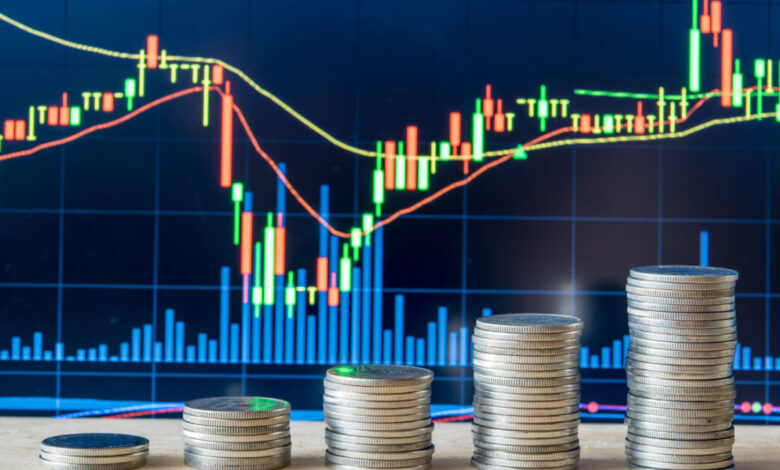

# **Descripción del proyecto**

En este proyecto, visualizaremos los precios de las acciones usando Seaborn y Matplotlib. Se consideran 4 acciones, incluidas JP Morgan Chase (JP), Procter and Gamble (P&G) (PG), Apple (AAPL) y United Airlines (UAL).

Usando el conjunto de datos stock_daily_prices.csv y stocks_daily_returns.csv incluidos en el Classroom del curso, haz lo siguiente:

1.   Importa las lbrerías que utilizarás en este proyecto.
2.   Importa ambos conjuntos de datos usando Pandas.
3.   Realiza un análisis exploratorio de los datos (EDA) básico donde muestres los primeros y últimos 10 registros, que verifiques el tipo de datos que tiene el dataset, que verifiques la cantidad de datos nulos que contiene el dataset.
4.   Calcula el precio promedio, el mínimo y máximo de cada característica de los datasets.
5.   Representar la matriz de correlaciones para los datasets.
6.   Define una función para convertir los valores del dataset acciones (que actualmente estan en dolares a pesos mexicanos, considerando una tasa de 19.36 pesos por dolar). Agrega cada conversión en una nueva columna.
7.   Con Matplotlib, representa diagramas de líneas que muestren los precios diarios de las 4 acciones en una sola cifra
8. Con Matplotlib, representa los 4 precios diarios de acciones en varias suplots.
9. Usando Matplotlib, representa los 4 plots en subplots una al lado de la otra (todas las figuras en una fila).
10. Con Matplotlib, representa el diagrama de dispersión entre los rendimientos diarios de Apple y JP Morgan.
11. Utilizando Seaborn, representa un diagrama de dispersión similar entre los rendimientos diarios de Apple y JP Morgan.
12. Supon que decides volverse alcista sobre AAPL y asignas el 70% de sus activos. También decides dividir en partes iguales el resto de sus activos en otras acciones (JPM, PG y UAL). Con Matplotlib, representa un gráfico circular que muestre estas asignaciones. Utiliza el atributo 'explode' para aumentar la separación entre AAPL y el resto de la cartera.
13. Usando Matplotlib, representa el histograma para los retornos de United Airlines y P&G usando 40 divisiones con color rojo. Muestra la media y la desviación estándar para ambas acciones en la parte superior de la figura. ¿Qué concluyes de este gráfico?
14. Con Seaborn, representa un mapa de calor que muestre las correlaciones entre los rendimientos diarios de las acciones. Comente la correlación entre UAL y P&G.
15. Representa un gráfico 3D que muestre todos los retornos diarios de JPM, AAPL y UAL [Se requiere investigación externa].
16.   Haz el escalamiento de todas las características del dataset acciones utilizando estandarización de datos.
17.   Escala todas las características del dataset rendimientos utilizando la normalización.
18.  Con Matplotlib, representa diagramas de líneas que muestren los precios diarios de las 4 acciones en una sola cifra, comparalos con los gráfico que habías realizado antes.


## **1.- IMPORTAR LIBRERÍAS**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## **2.- IMPORTAR DATOS**

In [ ]:
daily_prices_ds = pd.read_csv('/content/drive/MyDrive/datasets/P2-stocks_daily_prices.csv')
daily_returns_ds = pd.read_csv('/content/drive/MyDrive/datasets/P2-stocks_daily_returns.csv')

## **3.- ANÁLISIS EXPLORATORIO DE DATOS**

In [ ]:
daily_prices_ds.head(10)

,Date,AAPL,JPM,PG,UAL
0,1/2/2008,5.949703,29.448614,47.058838,29.915234
1,1/3/2008,5.952452,29.246094,47.058838,29.690800
2,1/4/2008,5.498071,28.582682,46.870098,31.000002
3,1/7/2008,5.424478,28.868999,47.175980,29.180000
4,1/8/2008,5.229351,27.723747,47.299629,24.389999
5,1/9/2008,5.478222,28.114801,47.208511,26.030001
6,1/10/2008,5.436081,28.862019,47.169464,32.189999
7,1/11/2008,5.273324,28.533800,45.672649,32.070000
8,1/14/2008,5.459290,28.882969,45.744232,32.930000
9,1/15/2008,5.161868,27.353619,45.360241,34.570000


In [ ]:
daily_prices_ds.tail(10)

,Date,AAPL,JPM,PG,UAL
3632,6/6/2022,146.139999,129.729996,145.320007,44.759998
3633,6/7/2022,148.710007,130.070007,146.940002,46.450001
3634,6/8/2022,147.960007,128.000000,145.110001,44.599998
3635,6/9/2022,142.639999,125.309998,142.490005,42.700001
3636,6/10/2022,137.130005,119.550003,141.949997,41.160000
3637,6/13/2022,131.880005,115.989998,138.149994,37.020000
3638,6/14/2022,132.759995,114.059998,133.839996,36.990002
3639,6/15/2022,135.429993,115.410004,132.509995,37.889999
3640,6/16/2022,130.059998,113.430000,133.320007,34.779999
3641,6/17/2022,131.559998,113.029999,132.360001,36.279999


In [ ]:
daily_returns_ds.head(10)

,Date,AAPL,JPM,PG,UAL
0,1/2/2008,0.000000,0.000000,0.000000,0.000000
1,1/3/2008,0.046203,-0.687708,0.000000,-0.750233
2,1/4/2008,-7.633517,-2.268378,-0.401072,4.409454
3,1/7/2008,-1.338518,1.001718,0.652615,-5.870973
4,1/8/2008,-3.597157,-3.967066,0.262103,-16.415356
5,1/9/2008,4.759115,1.410539,-0.192640,6.724073
6,1/10/2008,-0.769237,2.657736,-0.082712,23.664993
7,1/11/2008,-2.994012,-1.137199,-3.173271,-0.372783
8,1/14/2008,3.526524,1.223702,0.156730,2.681636
9,1/15/2008,-5.447997,-5.294990,-0.839431,4.980259


In [ ]:
daily_returns_ds.tail(10)

,Date,AAPL,JPM,PG,UAL
3632,6/6/2022,0.522764,-0.330369,-0.390700,0.742737
3633,6/7/2022,1.758593,0.262092,1.114778,3.775698
3634,6/8/2022,-0.504337,-1.591456,-1.245407,-3.982782
3635,6/9/2022,-3.595571,-2.101564,-1.805523,-4.260085
3636,6/10/2022,-3.862868,-4.596596,-0.378980,-3.606559
3637,6/13/2022,-3.828484,-2.977838,-2.677001,-10.058308
3638,6/14/2022,0.667265,-1.663937,-3.119796,-0.081034
3639,6/15/2022,2.011147,1.183593,-0.993725,2.433084
3640,6/16/2022,-3.965145,-1.715625,0.611284,-8.207972
3641,6/17/2022,1.153314,-0.352642,-0.720077,4.312824


In [ ]:
daily_prices_ds.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3642 entries, 0 to 3641
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    3642 non-null   object 
 1   AAPL    3642 non-null   float64
 2   JPM     3642 non-null   float64
 3   PG      3642 non-null   float64
 4   UAL     3642 non-null   float64
dtypes: float64(4), object(1)
memory usage: 142.4+ KB


In [ ]:
daily_returns_ds.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3642 entries, 0 to 3641
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    3642 non-null   object 
 1   AAPL    3642 non-null   float64
 2   JPM     3642 non-null   float64
 3   PG      3642 non-null   float64
 4   UAL     3642 non-null   float64
dtypes: float64(4), object(1)
memory usage: 142.4+ KB


In [ ]:
daily_prices_ds.isnull().sum()

,0
Date,0
AAPL,0
JPM,0
PG,0
UAL,0


In [ ]:
daily_returns_ds.isnull().sum()

,0
Date,0
AAPL,0
JPM,0
PG,0
UAL,0


# **4.- PRECIOS MEDIOS**

In [ ]:
daily_prices_ds.select_dtypes(include="number").mean()

,0
AAPL,39.648625
JPM,64.927239
PG,73.729653
UAL,43.183288


In [ ]:
daily_returns_ds.select_dtypes(include="number").mean()

,0
AAPL,0.105180
JPM,0.069331
PG,0.035579
UAL,0.098866


In [ ]:
daily_prices_ds.select_dtypes(include="number").min()

,0
AAPL,2.387943
JPM,11.545819
PG,29.637867
UAL,3.130000


In [ ]:
daily_returns_ds.select_dtypes(include="number").min()

,0
AAPL,-17.919513
JPM,-20.727418
PG,-8.737353
UAL,-36.770882


In [ ]:
daily_prices_ds.select_dtypes(include="number").max()

,0
AAPL,181.511704
JPM,169.500061
PG,163.410004
UAL,96.699997


In [ ]:
daily_returns_ds.select_dtypes(include="number").max()

,0
AAPL,13.904950
JPM,25.096737
PG,12.009046
UAL,68.537079


# **5.- MATRIZ DE CORRELACIÓN**

<Axes: >

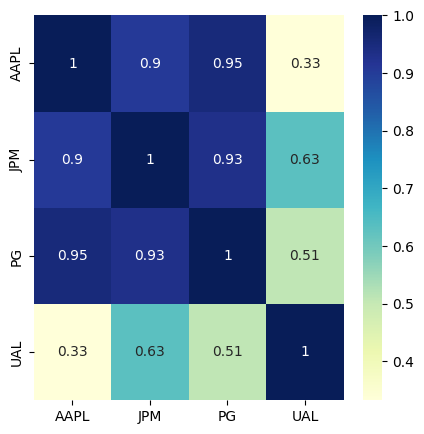

In [ ]:
daily_prices_corr = daily_prices_ds.corr(numeric_only= True)
f, ax = plt.subplots(figsize=(5,5))
sns.heatmap(daily_prices_corr, annot=True, cmap='YlGnBu')

<Axes: >

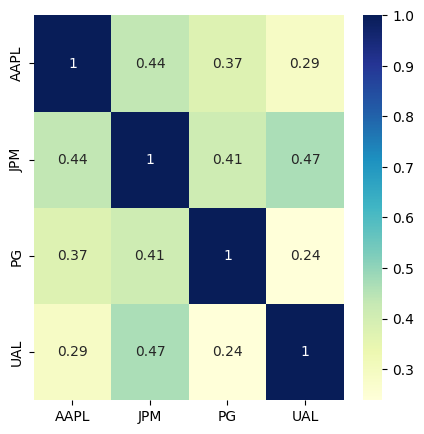

In [ ]:
daily_returns_corr = daily_returns_ds.corr(numeric_only= True)
f, ax = plt.subplots(figsize=(5,5))
sns.heatmap(daily_returns_corr, annot=True, cmap='YlGnBu')

# **6.- FUNCIÓN DE CONVERSIÓN**

In [ ]:
def to_pesos(dollars):
    return dollars * 19.36

# **7.- DIAGRAMAS DE LÍNEAS**

In [ ]:
# Lista de columnas numéricas (share_dp)
share_dp = daily_prices_ds.select_dtypes(include="number").columns

for col in share_dp:
    daily_prices_ds[f'{col}_MXN'] = daily_prices_ds[col].apply(to_pesos)

daily_prices_ds.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3642 entries, 0 to 3641
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      3642 non-null   object 
 1   AAPL      3642 non-null   float64
 2   JPM       3642 non-null   float64
 3   PG        3642 non-null   float64
 4   UAL       3642 non-null   float64
 5   AAPL_MXN  3642 non-null   float64
 6   JPM_MXN   3642 non-null   float64
 7   PG_MXN    3642 non-null   float64
 8   UAL_MXN   3642 non-null   float64
dtypes: float64(8), object(1)
memory usage: 256.2+ KB


In [ ]:
share_dr = daily_returns_ds.select_dtypes(include="number").columns

for col in share_dr:
    daily_returns_ds[f'{col}_MXN'] = daily_returns_ds[col].apply(to_pesos)

daily_returns_ds.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3642 entries, 0 to 3641
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      3642 non-null   object 
 1   AAPL      3642 non-null   float64
 2   JPM       3642 non-null   float64
 3   PG        3642 non-null   float64
 4   UAL       3642 non-null   float64
 5   AAPL_MXN  3642 non-null   float64
 6   JPM_MXN   3642 non-null   float64
 7   PG_MXN    3642 non-null   float64
 8   UAL_MXN   3642 non-null   float64
dtypes: float64(8), object(1)
memory usage: 256.2+ KB


# **8.- REPRESENTACIÓN DE SUBPLOTS MÚLTIPLES**

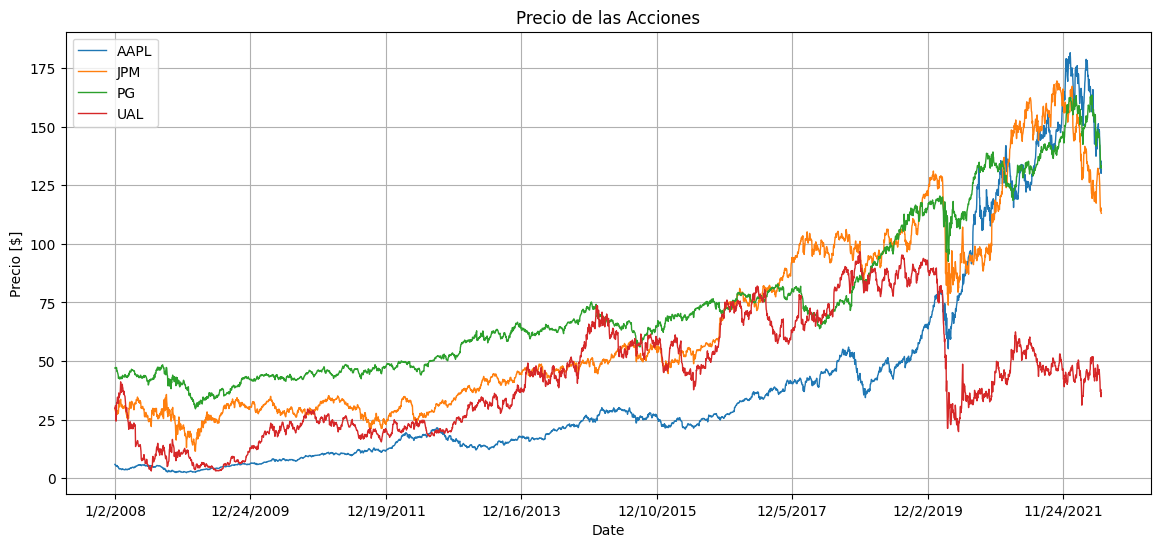

In [ ]:
daily_prices_ds.plot(x='Date', y=['AAPL', 'JPM', 'PG', 'UAL'],
                      linewidth=1, figsize=(14, 6))
plt.ylabel('Precio [$]')
plt.title('Precio de las Acciones')
plt.grid(True)
plt.show()

# **9.- REPRESENTACIÓN DE SUBPLOTS LATERALES**

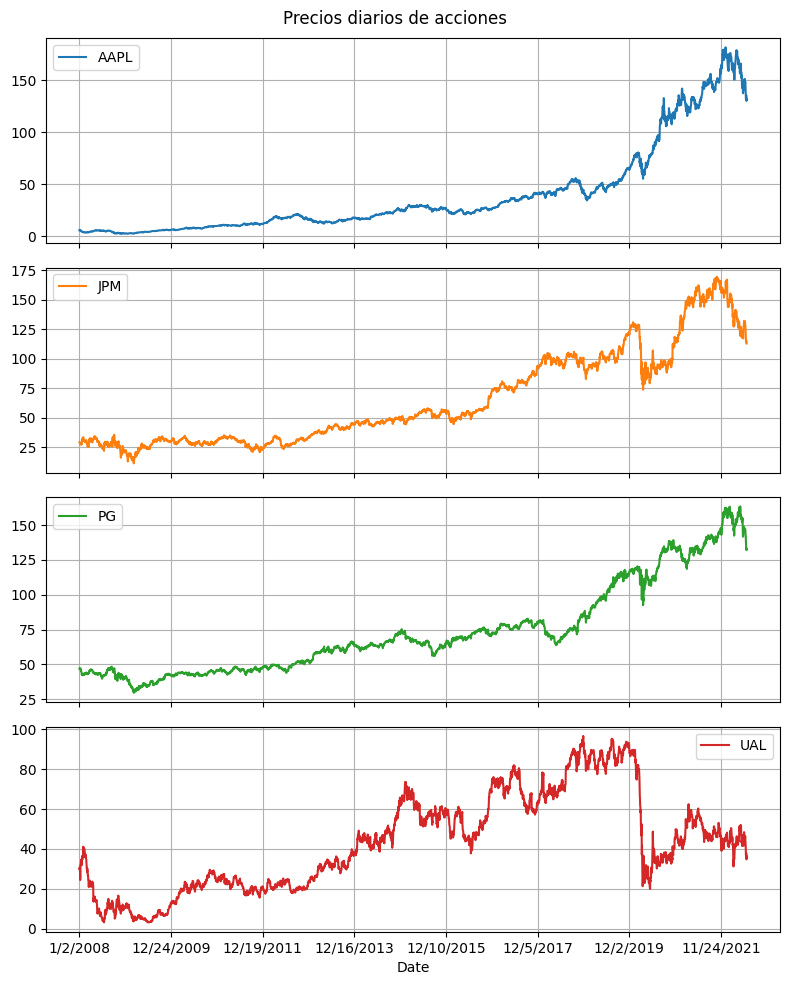

In [ ]:
daily_prices_ds.plot(x='Date', y=['AAPL', 'JPM', 'PG', 'UAL'], title='Precios diarios de acciones',
                      subplots=True, grid=True, figsize=(8, 10))
plt.tight_layout()
plt.show()

# **10.- REPRESENTACIÓN DE DIAGRAMA DE DISPERSIÓN**

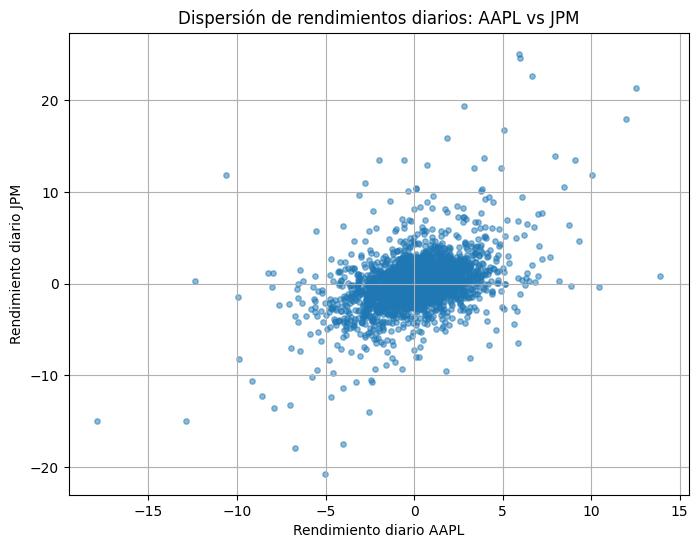

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(daily_returns_ds['AAPL'], daily_returns_ds['JPM'], alpha=0.5, s=15)

plt.title('Dispersión de rendimientos diarios: AAPL vs JPM')
plt.xlabel('Rendimiento diario AAPL')
plt.ylabel('Rendimiento diario JPM')
plt.grid(True)
plt.show()

# **11.- DIAGRAMA DE DISPERSIÓN CON SEABORN**

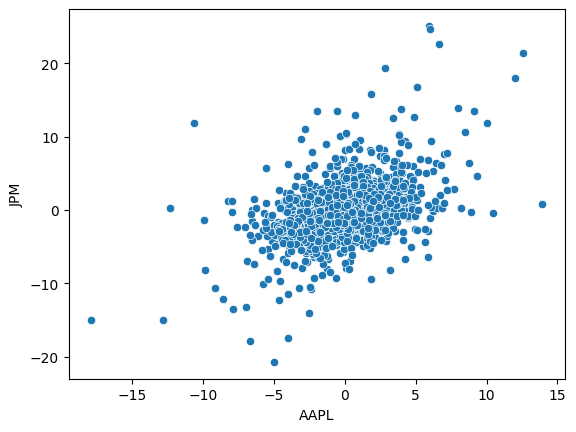

In [ ]:
sns.scatterplot(x = 'AAPL', y = 'JPM', data = daily_returns_ds);

# **12.- GRÁFICO DE PASTEL**

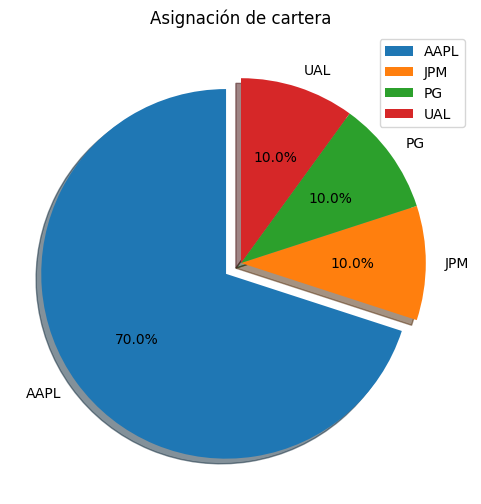

In [ ]:
my_data = {'Asignacion %': [70, 10, 10, 10]}
explode = (0.1, 0, 0, 0)  # separar AAPL del resto

portfolio_df = pd.DataFrame(data=my_data, index=['AAPL', 'JPM', 'PG', 'UAL'])

portfolio_df.plot.pie(y='Asignacion %', explode=explode, figsize=(6,6),
                       autopct='%1.1f%%', shadow=True, startangle=90)

plt.title('Asignación de cartera')
plt.ylabel('')
plt.show()

# **13.- REPRESENTACIÓN DE HISTOGRAMA**

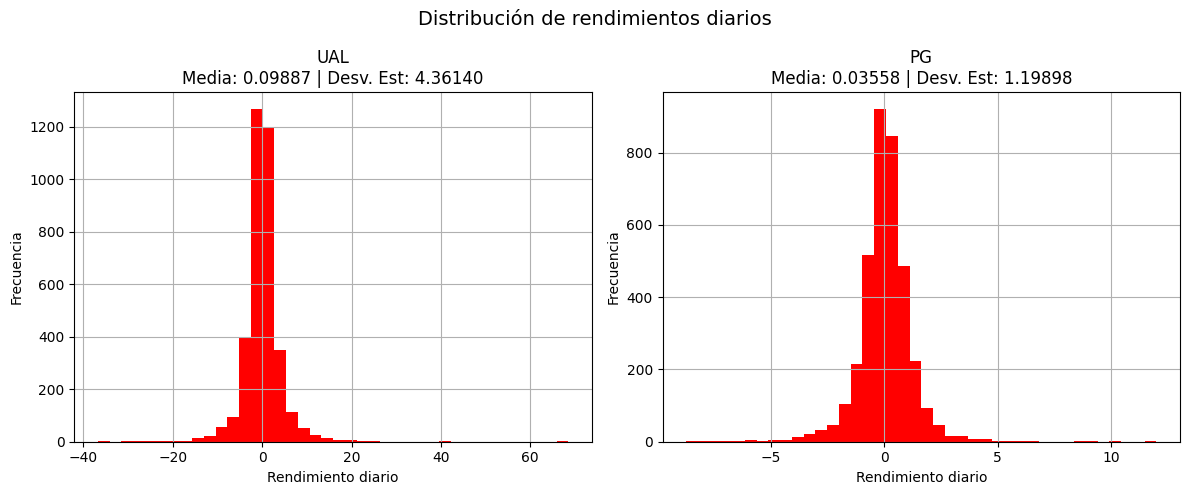

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Calcular estadísticas
ual_mean = daily_returns_ds['UAL'].mean()
ual_std = daily_returns_ds['UAL'].std()
pg_mean = daily_returns_ds['PG'].mean()
pg_std = daily_returns_ds['PG'].std()

# Histograma UAL
axes[0].hist(daily_returns_ds['UAL'], bins=40, color='red')
axes[0].set_title(f'UAL\nMedia: {ual_mean:.5f} | Desv. Est: {ual_std:.5f}')
axes[0].set_xlabel('Rendimiento diario')
axes[0].set_ylabel('Frecuencia')
axes[0].grid(True)

# Histograma PG
axes[1].hist(daily_returns_ds['PG'], bins=40, color='red')
axes[1].set_title(f'PG\nMedia: {pg_mean:.5f} | Desv. Est: {pg_std:.5f}')
axes[1].set_xlabel('Rendimiento diario')
axes[1].set_ylabel('Frecuencia')
axes[1].grid(True)

fig.suptitle('Distribución de rendimientos diarios', fontsize=14)
plt.tight_layout()
plt.show()

**Observacion**: ambas tienen forma de campana pero ual tiene más volatilidad, UAL puede ofrecer mayores ganancias potenciales en días buenos, pero también mayores pérdidas en días malos

# **14.- REPRESENTACIÓN DE MAPA DE CALOR**

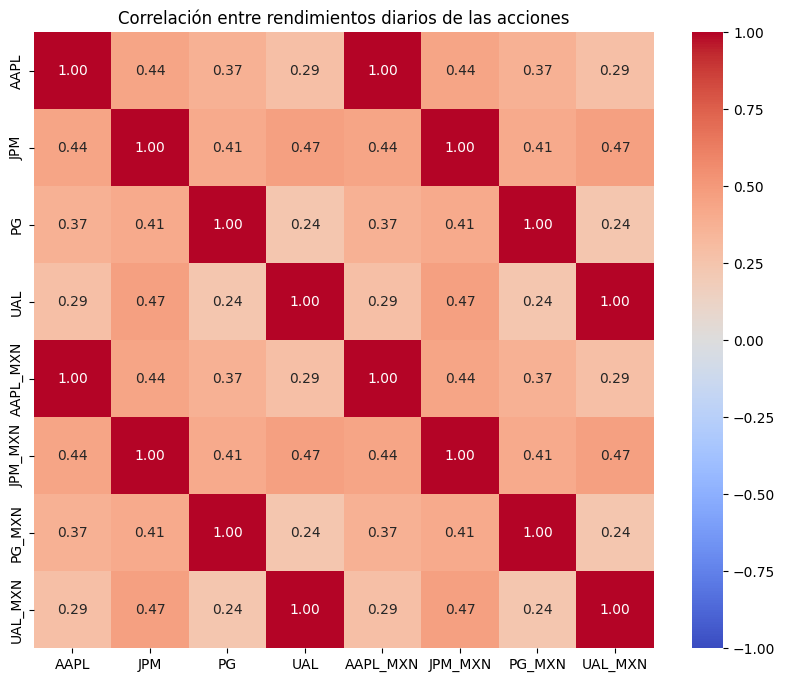

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(daily_returns_ds.corr(numeric_only=True), annot=True, cmap='coolwarm',
            vmin=-1, vmax=1, fmt=".2f")
plt.title('Correlación entre rendimientos diarios de las acciones')
plt.show()

# **15.- REPRESENTACIÓN DE GRÁFICO 3D**

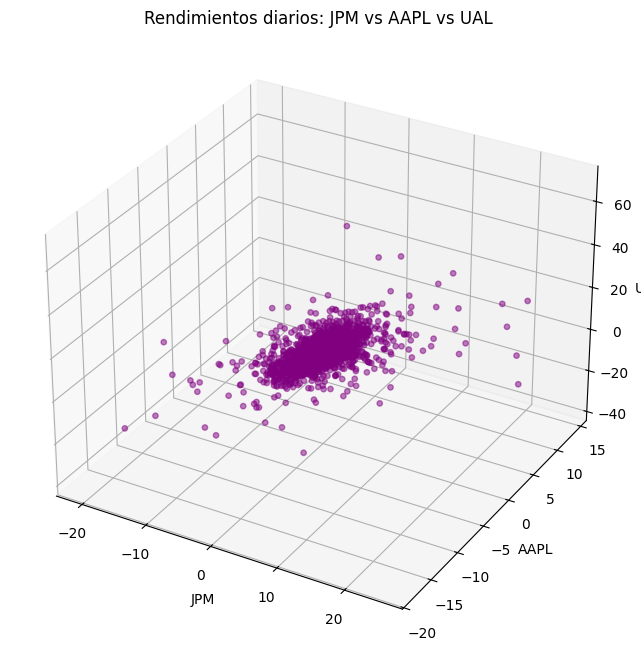

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # necesario para habilitar proyección 3D

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(daily_returns_ds['JPM'],
           daily_returns_ds['AAPL'],
           daily_returns_ds['UAL'],
           c='purple', alpha=0.5, s=15)

ax.set_xlabel('JPM')
ax.set_ylabel('AAPL')
ax.set_zlabel('UAL')
ax.set_title('Rendimientos diarios: JPM vs AAPL vs UAL')

plt.show()

# **16.- ESTANDARIZACIÓN DE DATOS**

In [ ]:
# Seleccionar solo las columnas numéricas (acciones)
features = daily_prices_ds.select_dtypes(include="number").columns

scaler = StandardScaler()
scaled_data = scaler.fit_transform(daily_prices_ds[features])

# Convertir de nuevo a DataFrame, conservando nombres de columnas e índice
daily_prices_scaled = pd.DataFrame(scaled_data, columns=features, index=daily_prices_ds.index)

daily_prices_scaled.head()

,AAPL,JPM,PG,UAL,AAPL_MXN,JPM_MXN,PG_MXN,UAL_MXN
0,-0.777889,-0.894625,-0.817636,-0.544015,-0.777889,-0.894625,-0.817636,-0.544015
1,-0.777826,-0.899731,-0.817636,-0.553217,-0.777826,-0.899731,-0.817636,-0.553217
2,-0.788315,-0.916460,-0.823422,-0.499537,-0.788315,-0.916460,-0.823422,-0.499537
3,-0.790013,-0.909240,-0.814045,-0.574161,-0.790013,-0.909240,-0.814045,-0.574161
4,-0.794518,-0.938119,-0.810254,-0.770560,-0.794518,-0.938119,-0.810254,-0.770560


# **17.- NORMALIZACIÓN DE DATOS**

In [ ]:
# Seleccionar solo las columnas numéricas (rendimientos)
features = daily_returns_ds.select_dtypes(include="number").columns

scaler = MinMaxScaler()
normalized_data = scaler.fit_transform(daily_returns_ds[features])

# Convertir de nuevo a DataFrame, conservando nombres de columnas e índice
daily_returns_normalized = pd.DataFrame(normalized_data, columns=features, index=daily_returns_ds.index)

daily_returns_normalized.head()

,AAPL,JPM,PG,UAL,AAPL_MXN,JPM_MXN,PG_MXN,UAL_MXN
0,0.563074,0.452325,0.421150,0.349175,0.563074,0.452325,0.421150,0.349175
1,0.564525,0.437318,0.421150,0.342051,0.564525,0.437318,0.421150,0.342051
2,0.323210,0.402823,0.401818,0.391047,0.323210,0.402823,0.401818,0.391047
3,0.521014,0.474185,0.452607,0.293424,0.521014,0.474185,0.452607,0.293424
4,0.450042,0.365754,0.433784,0.193295,0.450042,0.365754,0.433784,0.193295


# **18.- DIAGRAMA DE LÍNEAS CON MATPLOTLIB**

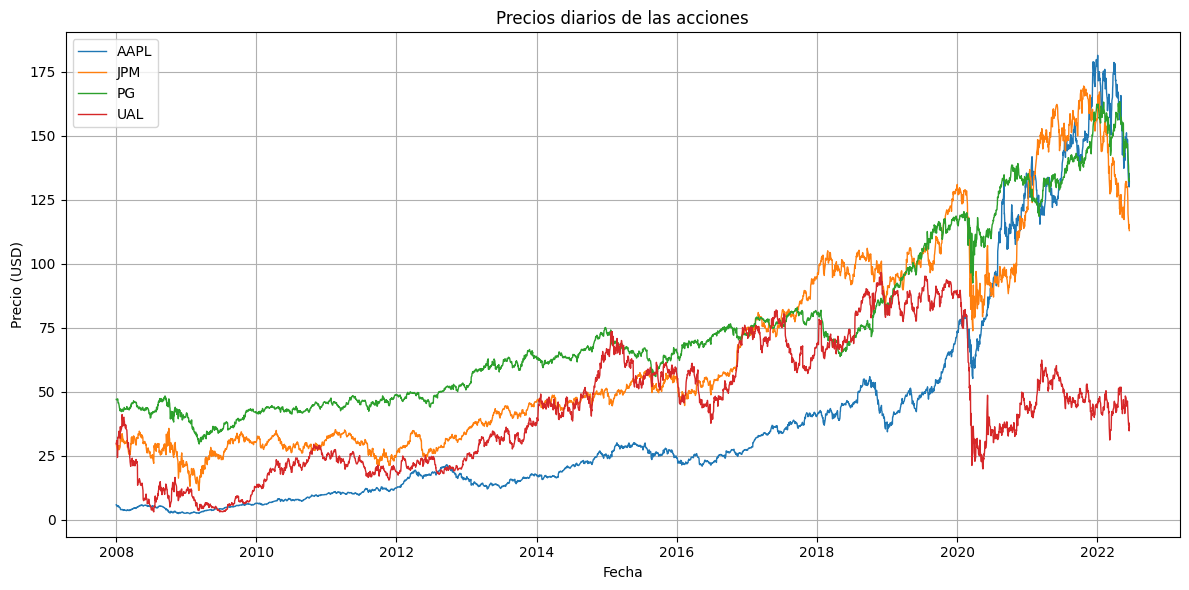

In [ ]:
plt.figure(figsize=(12, 6))
daily_prices_ds['Date'] = pd.to_datetime(daily_prices_ds['Date'])

for col in ['AAPL', 'JPM', 'PG', 'UAL']:
    plt.plot(daily_prices_ds['Date'], daily_prices_ds[col], label=col, linewidth=1)

plt.title('Precios diarios de las acciones')
plt.xlabel('Fecha')
plt.ylabel('Precio (USD)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()